Shape: (2200, 8)
Missing values: 0 | Duplicate rows: 0
Number of crops: 22 | Samples per crop: [100]
              count    mean    std    min    25%    50%     75%     max
N            2200.0   50.55  36.92   0.00  21.00  37.00   84.25  140.00
P            2200.0   53.36  32.99   5.00  28.00  51.00   68.00  145.00
K            2200.0   48.15  50.65   5.00  20.00  32.00   49.00  205.00
temperature  2200.0   25.62   5.06   8.83  22.77  25.60   28.56   43.68
humidity     2200.0   71.48  22.26  14.26  60.26  80.47   89.95   99.98
ph           2200.0    6.47   0.77   3.50   5.97   6.43    6.92    9.94
rainfall     2200.0  103.46  54.96  20.21  64.55  94.87  124.27  298.56


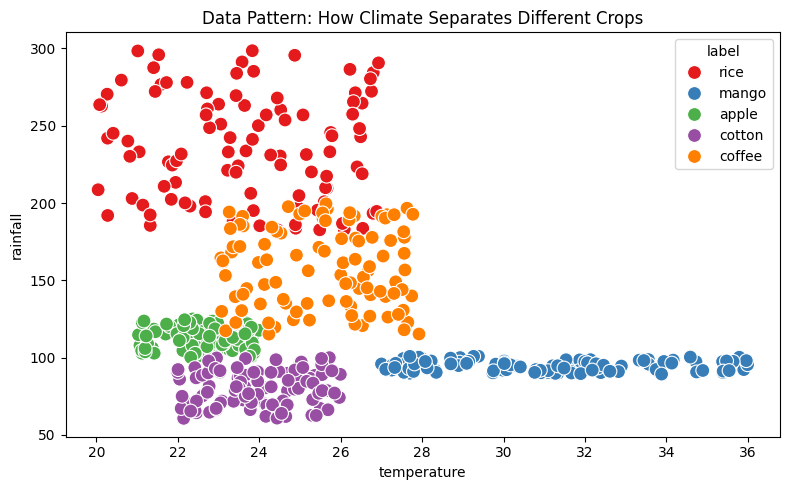


Ensemble Model Accuracy: 99.32%


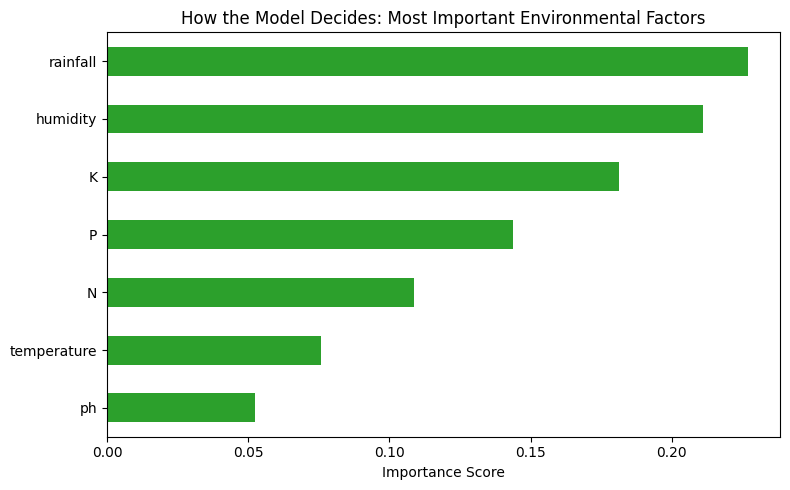

rainfall       0.227
humidity       0.211
K              0.181
P              0.144
N              0.109
temperature    0.076
ph             0.052
dtype: float64

               precision    recall  f1-score   support

       apple      1.000     1.000     1.000        23
      banana      1.000     1.000     1.000        21
   blackgram      1.000     1.000     1.000        20
    chickpea      1.000     1.000     1.000        26
     coconut      1.000     1.000     1.000        27
      coffee      1.000     1.000     1.000        17
      cotton      1.000     1.000     1.000        17
      grapes      1.000     1.000     1.000        14
        jute      0.920     1.000     0.958        23
 kidneybeans      1.000     1.000     1.000        20
      lentil      0.917     1.000     0.957        11
       maize      1.000     1.000     1.000        21
       mango      1.000     1.000     1.000        19
   mothbeans      1.000     0.958     0.979        24
    mungbean      1.000  

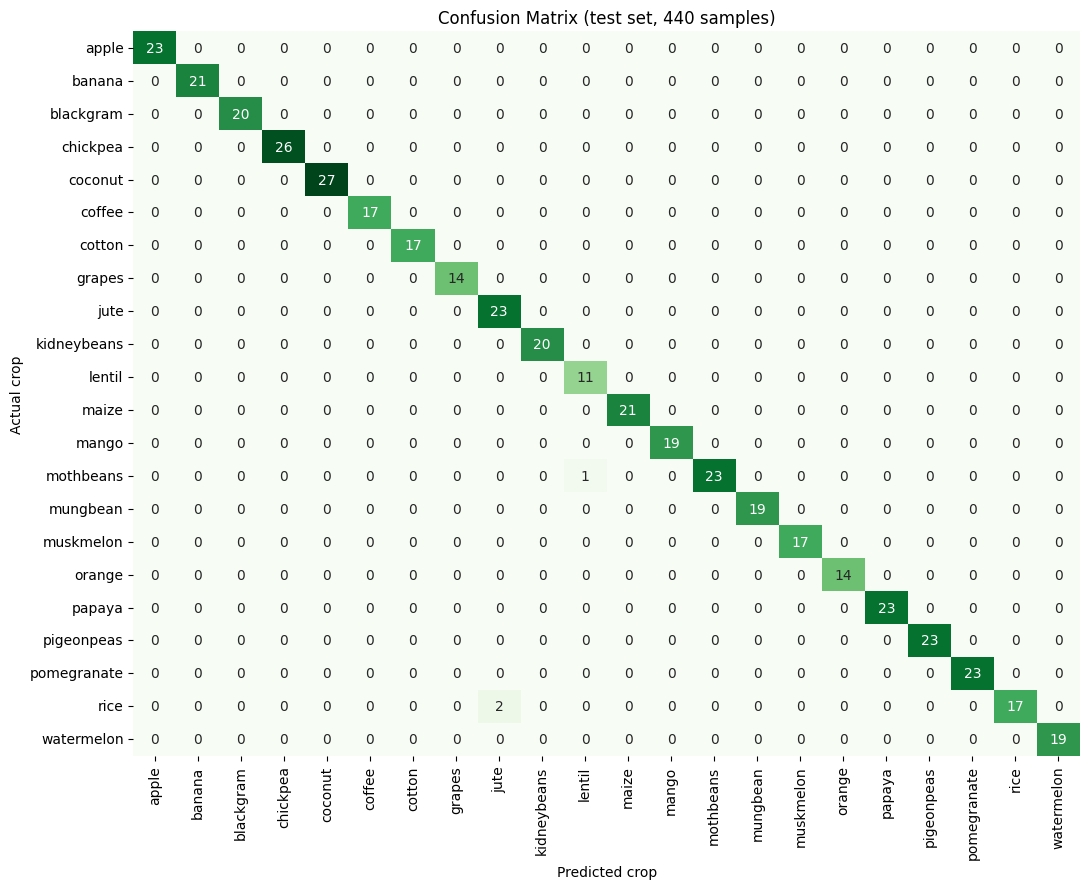

Misclassified (actual -> predicted): [('rice', 'jute'), ('rice', 'jute'), ('mothbeans', 'lentil')]

Fold accuracies: [ 99.55  99.32 100.    99.77  99.09]
Mean accuracy: 99.55% (+/- 0.32)

Recommended crop: rice


In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# ---------- 1. LOAD AND UNDERSTAND DATA ----------
url = "https://raw.githubusercontent.com/delosreyesjohnpaul/Crop-Recommendation-System/main/Crop_recommendation.csv"
df = pd.read_csv(url)
print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum(), "| Duplicate rows:", df.duplicated().sum())
print("Number of crops:", df['label'].nunique(), "| Samples per crop:", df['label'].value_counts().unique())
print(df.describe().T.round(2))

# ---------- 2. GRAPH 1: CLIMATE PATTERN ----------
sample_crops = df[df['label'].isin(['mango', 'apple', 'rice', 'cotton', 'coffee'])]
plt.figure(figsize=(8, 5))
sns.scatterplot(data=sample_crops, x='temperature', y='rainfall', hue='label', s=100, palette='Set1')
plt.title("Data Pattern: How Climate Separates Different Crops")
plt.tight_layout()
plt.show()

# ---------- 3. SPLIT AND NORMALIZE ----------
X = df.drop('label', axis=1)
y = df['label']
X_train_raw, X_test_raw, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)   # fit on training data only
X_test = scaler.transform(X_test_raw)

# ---------- 4. TRAIN RANDOM FOREST ----------
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(f"\nEnsemble Model Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%")

# ---------- 5. GRAPH 2: FEATURE IMPORTANCE ----------
importances = pd.Series(model.feature_importances_, index=X.columns)
plt.figure(figsize=(8, 5))
importances.sort_values().plot(kind='barh', color='#2ca02c')
plt.title("How the Model Decides: Most Important Environmental Factors")
plt.xlabel("Importance Score")
plt.tight_layout()
plt.show()
print(importances.sort_values(ascending=False).round(3))

# ---------- 6. DETAILED EVALUATION ----------
print("\n", classification_report(y_test, y_pred, digits=3))
labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)
plt.figure(figsize=(11, 9))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=labels, yticklabels=labels, cbar=False)
plt.xlabel("Predicted crop"); plt.ylabel("Actual crop")
plt.title("Confusion Matrix (test set, 440 samples)")
plt.xticks(rotation=90); plt.tight_layout()
plt.show()
wrong = [(a, p) for a, p in zip(y_test, y_pred) if a != p]
print("Misclassified (actual -> predicted):", wrong)

# ---------- 7. CROSS-VALIDATION ----------
pipe = make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=100, random_state=42))
scores = cross_val_score(pipe, X, y, cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42))
print("\nFold accuracies:", (scores * 100).round(2))
print(f"Mean accuracy: {scores.mean() * 100:.2f}% (+/- {scores.std() * 100:.2f})")

# ---------- 8. RECOMMEND A CROP FOR NEW CONDITIONS ----------
def recommend_crop(N, P, K, temperature, humidity, ph, rainfall):
    row = pd.DataFrame([[N, P, K, temperature, humidity, ph, rainfall]], columns=X.columns)
    return model.predict(scaler.transform(row))[0]

print("\nRecommended crop:", recommend_crop(N=90, P=42, K=43, temperature=20.9, humidity=82.0, ph=6.5, rainfall=203.0))